In [1]:
import os
#os.environ['CUDA_VISIBLE_DEVICES']='1'

from matplotlib import pyplot as plt 
import numpy as np
import pickle

import jax
import jax.numpy as jnp
import tqdm
import optax
import flax.linen as nn
from flax.metrics import tensorboard
from jax_resnet import resnet
from functools import partial

import datasets
import tensorflow_datasets as tfds
from importlib import reload
reload(datasets)

<module 'datasets' from '/net/CLUSTER/VAULT/users/lburon/internship/deep/shear2cosmo/datasets/__init__.py'>

In [2]:
# Define folders
SHEAR2COSMO_dir = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/deep/'
IMAGESIMS_dir = SHEAR2COSMO_dir+'tensorflow_datasets/'
LOGS_dir = SHEAR2COSMO_dir+'logs/'
MODELS_dir = SHEAR2COSMO_dir+'MODELS/'
PLOTS_dir = SHEAR2COSMO_dir+'PLOTS/'

In [3]:
# Define hyperparameters and suffix
batch_size = 64
N_maps = 2600*4
epochs = 200

# Define a scheduler for the learning rate
total_steps = int(epochs*N_maps/batch_size)

lri = 0.001

lr2 = 0.3 #0.3
step_2 = total_steps*0.1
step_2_ep = int(step_2*batch_size/N_maps)

print("total steps=",total_steps)
#print("step_2=",step_2)

lr_scheduler = optax.piecewise_constant_schedule(init_value=lri,
                  boundaries_and_scales={int(step_2):lr2,})
"""
init_value = 2e-3
nb_batch_train = 2600*5*0.6/batch_size

lr_scheduler = optax.piecewise_constant_schedule( init_value=init_value,
    boundaries_and_scales={
        int(nb_batch_train * 40): 0.5,
        int(nb_batch_train * 80): 0.66,
        int(nb_batch_train * 120): 0.66,
    },)
"""

loss_func = 'MSE'
# Define a simple MSE regression loss 
def loss_fn(params, batch):
    return jnp.mean(jnp.sum((model.apply(params, batch['x']) - batch['y'])**2,axis=-1))

case = 'cosmoslics_resnet18_loss'+loss_func+'_norm_1'+'_Nmaps'+str(N_maps)+'_lri'+str(lri)+'_lr2'+str(lr2)+'_step2_'+str(step_2_ep)+'_batch'+str(batch_size)+'_epochs'+str(epochs)
#case = 'cosmoslics_resnet18_loss'+loss_func+'norm_1'+'_Nmaps'+str(N_maps)+'_lri'+str(init_value)+'_lrsteps'+str(3)+'_batch'+str(batch_size)+'_epochs'+str(epochs)
print(case)

total steps= 32500
cosmoslics_resnet18_lossMSE_norm_1_Nmaps10400_lri0.001_lr20.3_step2_20_batch64_epochs200


In [4]:
# Define our compressor
ResNet = partial(resnet.ResNet18, n_classes=4)

class NeuralCompressor(nn.Module):
  @nn.compact
  def __call__(self, x):
    return ResNet()(x)

In [5]:
# Random seed for sampling from posterior
seed = jax.random.PRNGKey(0)

# Let's instantiate and initialize the model
model = NeuralCompressor()
params = model.init(jax.random.PRNGKey(42), jnp.zeros(shape=[1, 128, 128,1]))

# Initializes an optimizer and optimizer state
optimizer = optax.adam(learning_rate=lr_scheduler)
opt_state = optimizer.init(params)

summary_writer = tensorboard.SummaryWriter(LOGS_dir+case)

In [6]:
dset = tfds.load('cosmo_slics',split='train',data_dir=IMAGESIMS_dir)
# Let's collect a few examples to check their distributions
cutouts=[]
specz = []
for (batch, entry) in enumerate(dset.take(100)):
  cutouts.append(entry['Map'])
cutouts = np.stack(cutouts)
cutouts[np.isnan(cutouts)] = 0

2024-06-07 09:14:09.324016: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2024-06-07 09:14:09.326576: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


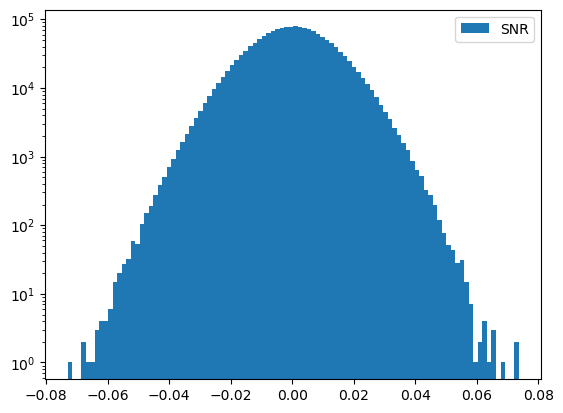

In [7]:
for i,b in enumerate(['SNR']):
  plt.hist(cutouts[...].flatten(),100, label=b);
plt.legend()
plt.yscale('log')

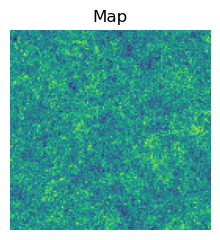

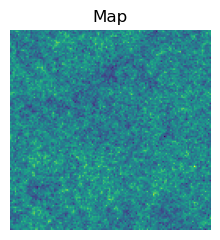

In [8]:
plt.figure(figsize=(15,3))
for i,b in enumerate(['Map']):
  plt.subplot(1,5,i+1)
  plt.imshow(cutouts[0,:,:]) #,vmin=-4,vmax=8
  plt.title(b)
  plt.axis('off')

plt.figure(figsize=(15,3))
for i,b in enumerate(['Map']):
  plt.subplot(1,5,i+1)
  plt.imshow(cutouts[1,:,:]) #,vmin=-4,vmax=8
  plt.title(b)
  plt.axis('off')

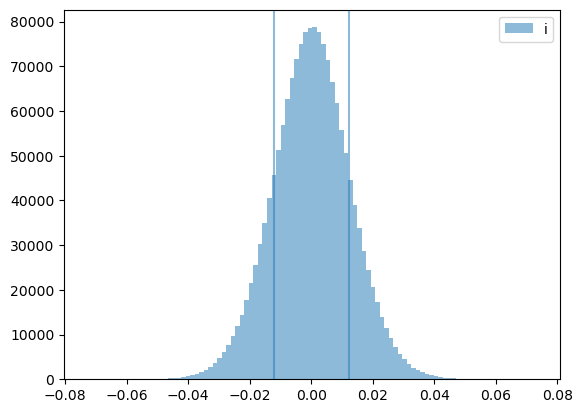

In [9]:
# Let's evaluate the noise standard deviation in each band, and apply range 
# compression accordingly

from astropy.stats import mad_std
scaling = []

for i,b in enumerate(['i']):
  plt.hist(cutouts[...].flatten(),100, label=b,alpha=0.5,);
  sigma = mad_std(cutouts[...].flatten())
  scaling.append(sigma)
  plt.axvline(sigma, color='C%d'%i,alpha=0.5)
  plt.axvline(-sigma, color='C%d'%i,alpha=0.5)
plt.legend()

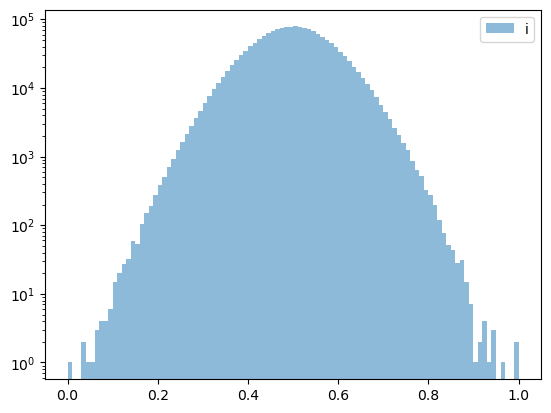

In [10]:
# Let's have a look at this distribution if we rescale it between 0 and 1 using max and min SNR values 
# over the dataset and center it

min_Mapmap = np.min(cutouts[...].flatten())
max_Mapmap = np.max(cutouts[...].flatten())

for i,b in enumerate([ 'i']):
  #plt.hist(cutouts[...].flatten()/scaling[i],100, label=b,alpha=0.5,
  plt.hist((cutouts[...].flatten()-min_Mapmap)/(max_Mapmap-min_Mapmap),100, label=b,alpha=0.5,
           range=[0,1]);
plt.legend()
plt.yscale('log')

In [ ]:
# a common approach for range compression is to apply arcsinh to suppress the
# high amplitude values
#for i,b in enumerate(['i']):
#  plt.hist(np.arcsinh(cutouts[...].flatten()/scaling[i]/3),100,
#           label=b, alpha=0.5,
#           range=[-5,5]);
#plt.legend()
#plt.yscale('log')

In [ ]:
# we can have a look at individual postage stamps with or without this scaling
#plt.subplot(121)
#plt.imshow(cutouts[0,:,:]/scaling[0])
#plt.title('Before')
#plt.subplot(122)
#plt.imshow(np.arcsinh(cutouts[0,:,:]/scaling[0]/3))
#plt.title('After');

In [11]:
import tensorflow as tf
def preprocessing(example):
  def range_compression(img):
    #return tf.clip_by_value(tf.math.asinh(tf.expand_dims(img, axis=-1) / tf.constant(scaling) / 3. ),-10,10)
    return tf.clip_by_value((tf.expand_dims(img, axis=-1) - min_Mapmap) / (max_Mapmap-min_Mapmap) ,-10,10)
  # Our preprocessing function only returns the postage stamps, and the shear
  return range_compression(example['Map']), example['CP']

In [12]:
#batch_size = 64

# Load the data
dset = tfds.load('cosmo_slics',split='train[:60%]',data_dir=IMAGESIMS_dir)
dset = dset.repeat()
dset = dset.shuffle(5000)
dset = dset.map(preprocessing)
dset = dset.batch(batch_size, drop_remainder=True)
dset = dset.prefetch(-1)
dset = dset.as_numpy_iterator()

In [13]:
dset_val = tfds.load('cosmo_slics',split='train[60%:80%]',data_dir=IMAGESIMS_dir)
dset_val = dset_val.repeat()
dset_val = dset_val.map(preprocessing)
dset_val = dset_val.batch(batch_size, drop_remainder=True)
dset_val = dset_val.prefetch(-1)
dset_val = dset_val.as_numpy_iterator()


In [14]:
@jax.jit
def update_model(params,  opt_state, batch):
  # Computes the gradients of the model
  loss, grads = jax.value_and_grad(loss_fn)(params, batch)

  # Computes the weights updates and apply them
  updates, opt_state = optimizer.update(grads, opt_state)
  params = optax.apply_updates(params, updates)

  return params, opt_state, loss

In [15]:
os.environ['TENSORBOARD_BINARY'] = '/home/lburon/micromamba/envs/SHEAR2COSMO/bin/tensorboard'
%load_ext tensorboard
%tensorboard --logdir={LOGS_dir}


In [ ]:
#batch = {'x': jnp.nan_to_num(batch[0]), 'y': batch[1]}  #NaN to 0

In [19]:
def plot_predictions(images, true_params, pred_params):
    param_names = [r"$\Omega_m$",r'$S_8$',r'$h$',r'$w_0$']
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    for i, ax in enumerate(axes.flatten()):
        ax.scatter(true_params[:, i], pred_params[:, i], alpha=0.5, label='Predicted vs True')
        t = np.linspace(min(true_params[:, i]), max(true_params[:, i]), 100)

        # Ideal line y = x
        ax.plot(t, t, color='k', label='Ideal y=x')

        # Linear regression line
        poly = np.polyfit(true_params[:, i], pred_params[:, i], 1)
        ax.plot(t, poly[1] + poly[0] * t, color='r', label=f'Fit: y = {poly[0]:.2f}x + {poly[1]:.2f}')


        # Formatting the plot
        ax.set_xlabel('True')
        ax.set_ylabel('Predicted')
        ax.set_title(f'{param_names[i]}: Pred vs True')
        ax.legend()
    
    plt.tight_layout()
    plt.show()
    plt.close()

def plot_in_out(images, true_params, pred_params):
    param_names = ["Om", "S8", "h", "w0"]
    n_images = 4
    images = images[:n_images]
    true_params = true_params[:n_images]
    pred_params = pred_params[:n_images]

    for i in range(n_images):
        plt.imshow(images[i, :, :, 0], cmap='bwr', origin='lower')
        plt.title(f'Input Image {i+1}')
        plt.axis('off')
        plt.show()

        true_str = ', '.join([f'{param_names[j]}= {true_params[i, j]:.4f}' for j in range(4)])
        pred_str = ', '.join([f'{param_names[j]}= {pred_params[i, j]:.4f}' for j in range(4)])

        print("shape : ", np.shape(images[i, :, :, 0]))
        print(f'True Parameters for Image {i+1}: {true_str}')
        print(f'Predicted Parameters for Image {i+1}: {pred_str}')
        print('\n')


  0%|          | 0/32500 [00:00<?, ?it/s]

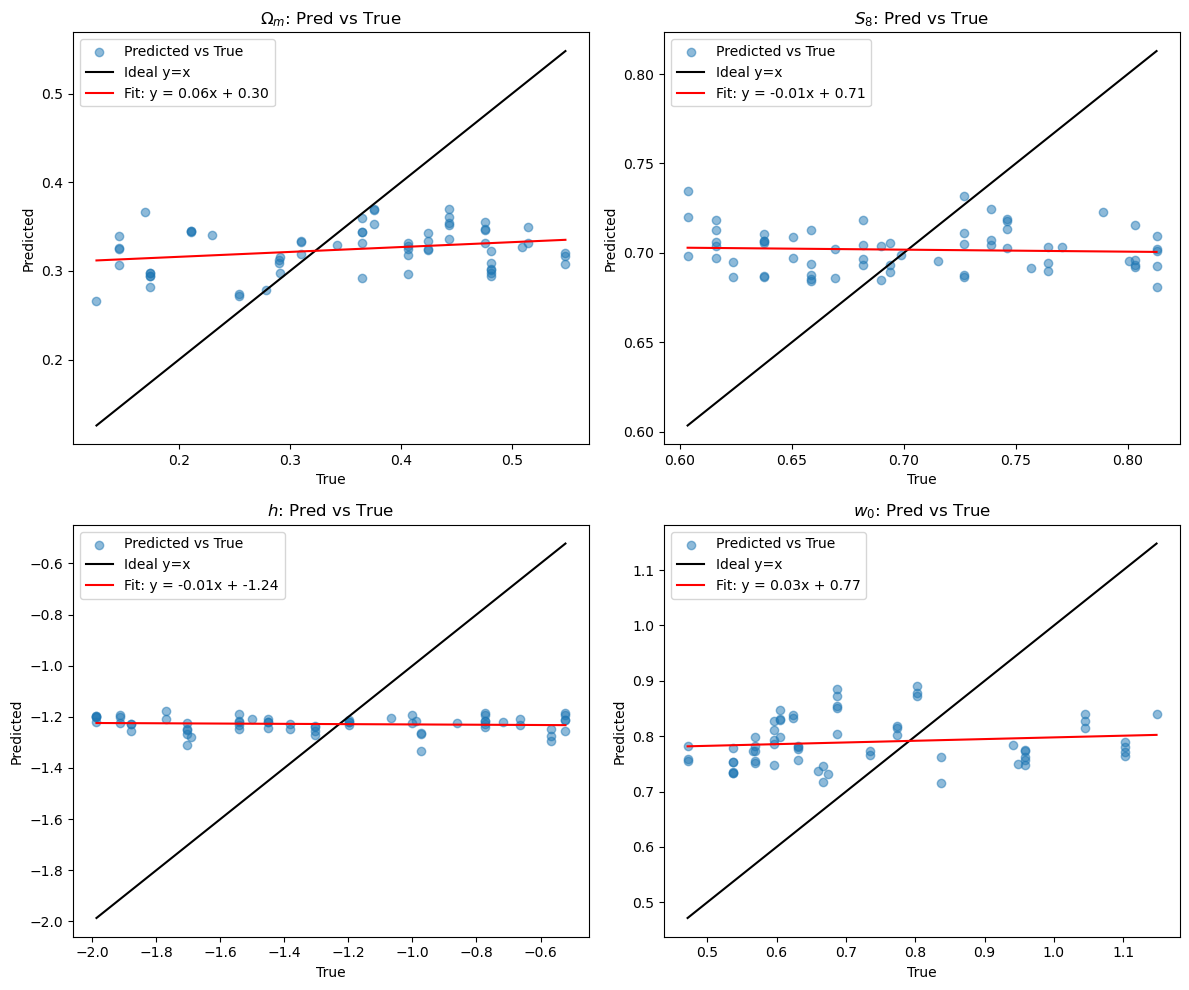

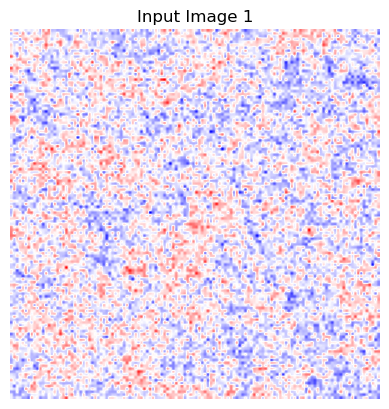

shape :  (128, 128)
True Parameters for Image 1: Om= 0.4247, S8= 0.6819, h= -1.1986, w0= 0.6313
Predicted Parameters for Image 1: Om= 0.3231, S8= 0.6930, h= -1.2191, w0= 0.7575




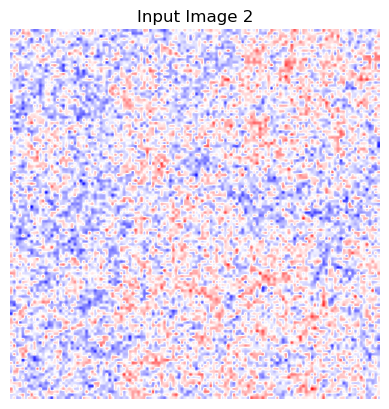

shape :  (128, 128)
True Parameters for Image 2: Om= 0.2106, S8= 0.7388, h= -0.5667, w0= 1.0454
Predicted Parameters for Image 2: Om= 0.3445, S8= 0.7072, h= -1.2485, w0= 0.8142




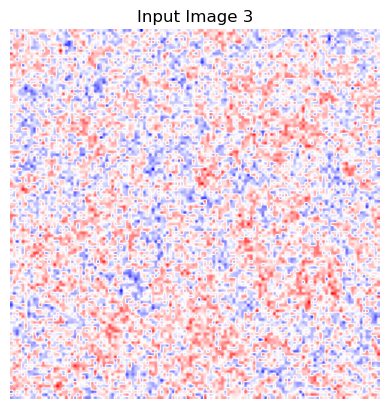

shape :  (128, 128)
True Parameters for Image 3: Om= 0.3652, S8= 0.7271, h= -1.5414, w0= 0.5958
Predicted Parameters for Image 3: Om= 0.3593, S8= 0.7318, h= -1.2464, w0= 0.8103




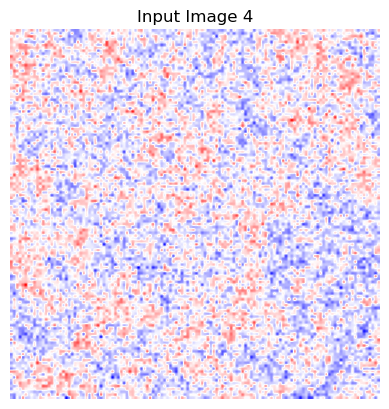

  0%|          | 8/32500 [00:04<3:53:02,  2.32it/s] 

shape :  (128, 128)
True Parameters for Image 4: Om= 0.3099, S8= 0.6940, h= -1.8784, w0= 0.7734
Predicted Parameters for Image 4: Om= 0.3189, S8= 0.6891, h= -1.2264, w0= 0.8156




 15%|█▌        | 4998/32500 [01:27<07:12, 63.59it/s]

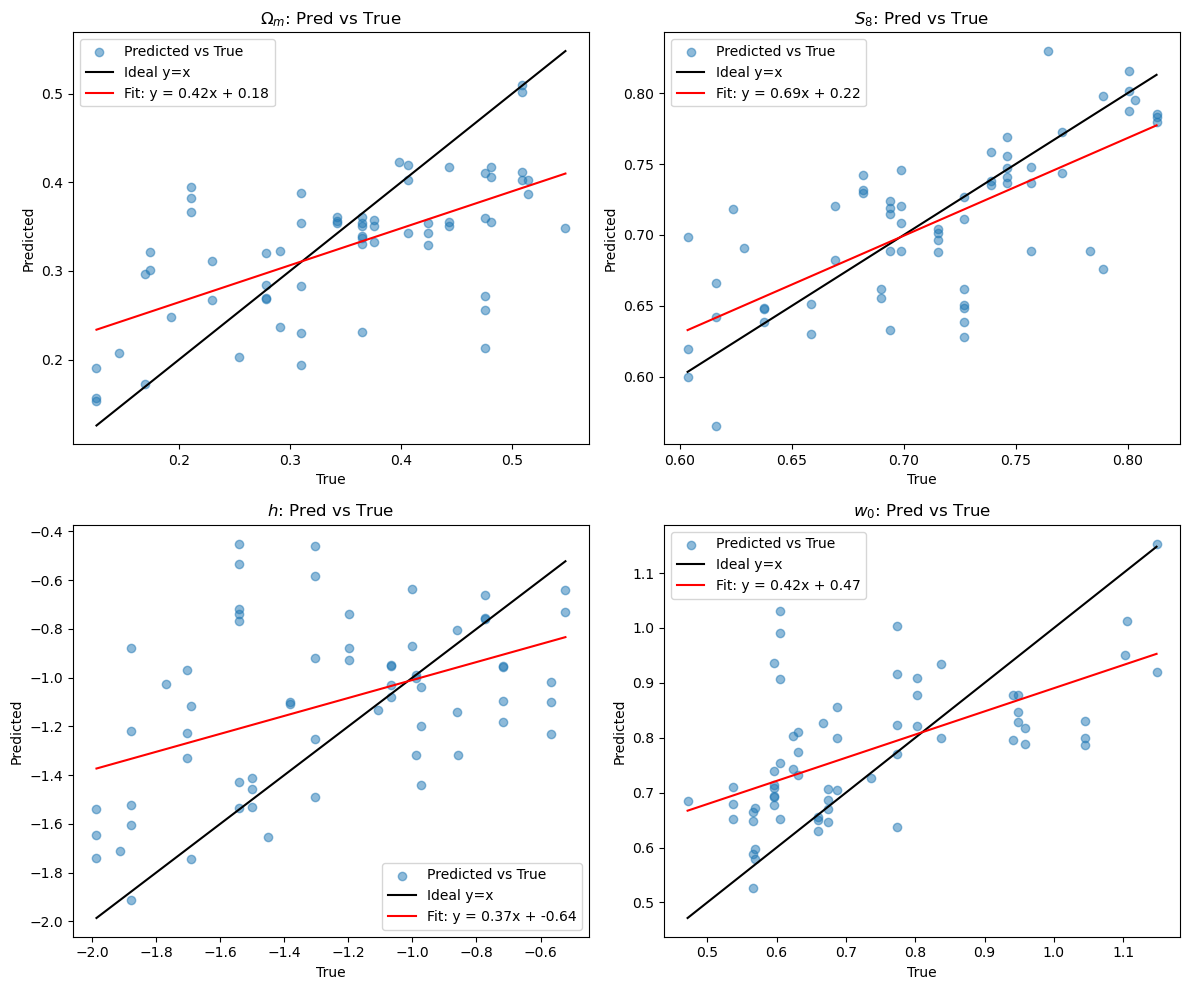

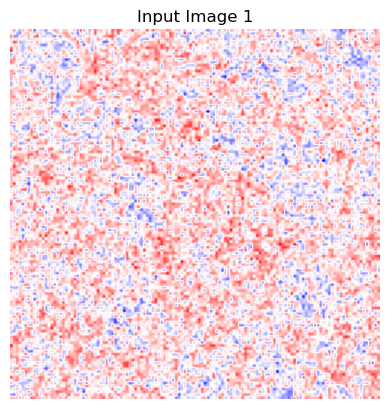

shape :  (128, 128)
True Parameters for Image 1: Om= 0.3425, S8= 0.8006, h= -1.5010, w0= 0.6602
Predicted Parameters for Image 1: Om= 0.3604, S8= 0.7875, h= -1.5323, w0= 0.6304




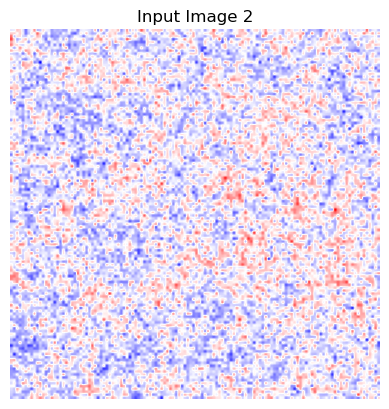

shape :  (128, 128)
True Parameters for Image 2: Om= 0.5095, S8= 0.6988, h= -0.7164, w0= 0.5652
Predicted Parameters for Image 2: Om= 0.4122, S8= 0.6883, h= -0.9557, w0= 0.6481




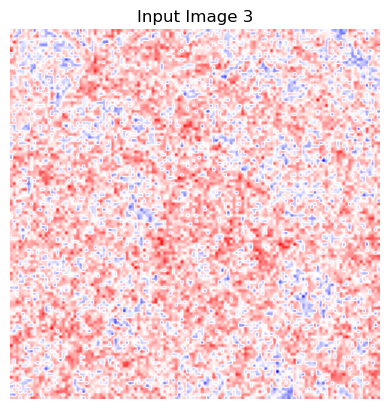

shape :  (128, 128)
True Parameters for Image 3: Om= 0.3099, S8= 0.6940, h= -1.8784, w0= 0.7734
Predicted Parameters for Image 3: Om= 0.3537, S8= 0.6333, h= -1.2201, w0= 0.7698




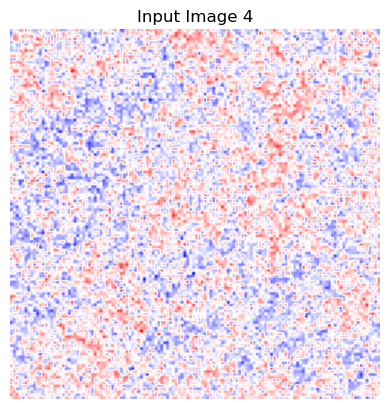

 15%|█▌        | 5005/32500 [01:29<44:37, 10.27it/s]

shape :  (128, 128)
True Parameters for Image 4: Om= 0.2106, S8= 0.7388, h= -0.5667, w0= 1.0454
Predicted Parameters for Image 4: Om= 0.3828, S8= 0.7350, h= -1.1008, w0= 0.7874




 31%|███       | 10000/32500 [02:53<05:53, 63.59it/s]

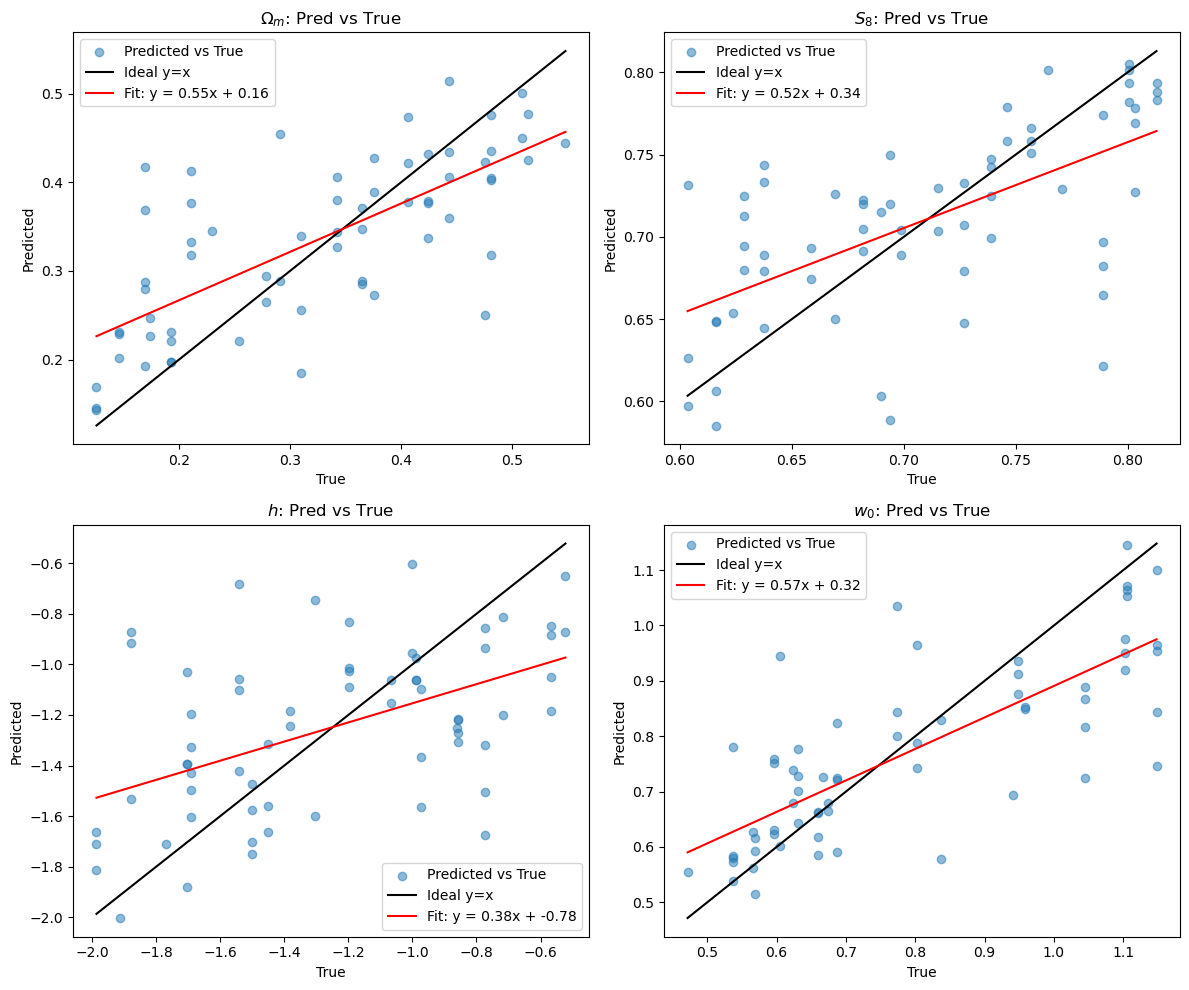

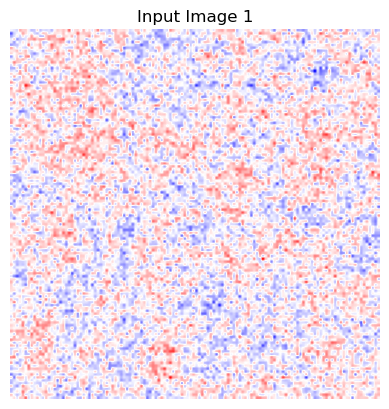

shape :  (128, 128)
True Parameters for Image 1: Om= 0.4815, S8= 0.6374, h= -0.7737, w0= 0.5371
Predicted Parameters for Image 1: Om= 0.4358, S8= 0.7436, h= -1.6731, w0= 0.5731




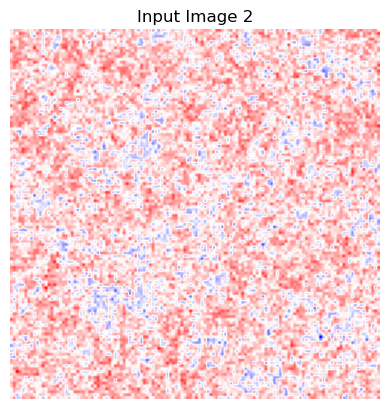

shape :  (128, 128)
True Parameters for Image 2: Om= 0.1928, S8= 0.6285, h= -0.8564, w0= 1.1055
Predicted Parameters for Image 2: Om= 0.1970, S8= 0.7249, h= -1.2708, w0= 1.0635




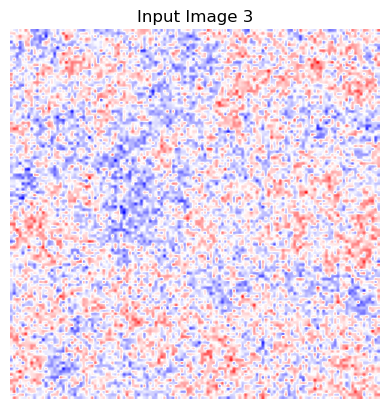

shape :  (128, 128)
True Parameters for Image 3: Om= 0.2536, S8= 0.6238, h= -1.7698, w0= 0.6670
Predicted Parameters for Image 3: Om= 0.2207, S8= 0.6534, h= -1.7119, w0= 0.7254




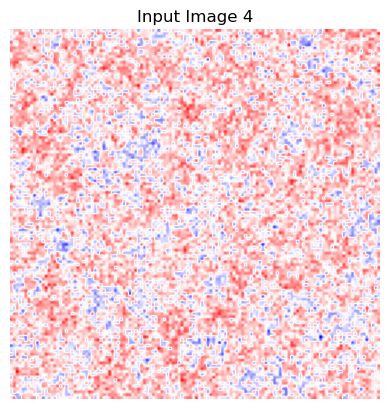

 31%|███       | 10007/32500 [02:55<39:18,  9.54it/s]

shape :  (128, 128)
True Parameters for Image 4: Om= 0.4062, S8= 0.8129, h= -1.9866, w0= 0.5689
Predicted Parameters for Image 4: Om= 0.4738, S8= 0.7881, h= -1.8117, w0= 0.5155




 32%|███▏      | 10338/32500 [03:01<06:29, 56.88it/s]


KeyboardInterrupt: 

In [20]:
# Create directory MODELS if necessary
#if not os.path.exists(MODELS_dir):
#   os.makedirs(MODELS_dir)

train_losses = []
val_losses = []
epochs_list = []
steps_per_epoch = N_maps // batch_size
epoch_count = 0

for i in tqdm.tqdm(range(total_steps)):
    batch = next(dset)  # Take next batch
    key, seed = jax.random.split(seed)
    batch = {'x': jnp.nan_to_num(batch[0]), 'y': batch[1]}  # NaN to 0

    # Apply the update function
    params, opt_state, loss = update_model(params, opt_state, batch)  # Update for new batch

    # Check validation loss at the beginning of each epoch
    if i % steps_per_epoch == 0 and i > 0:
        summary_writer.scalar('train_loss', loss, epoch_count)
        summary_writer.scalar('learning_rate', lr_scheduler(i), epoch_count)

        train_losses.append(loss)
        epochs_list.append(epoch_count)
        
        batch = next(dset_val)
        batch = {'x': jnp.nan_to_num(batch[0]), 'y': batch[1]}
        loss_val = loss_fn(params, batch)
        summary_writer.scalar('val_loss', loss_val, epoch_count)
        val_losses.append(loss_val)
        
        epoch_count += 1

    # Save model parameters
    if i % 5000 == 0:
        with open(MODELS_dir + case + '_temp' + str(i) + '.pckl', 'wb') as handle:
            pickle.dump(params, handle, protocol=pickle.HIGHEST_PROTOCOL)

        plot_predict = 1 ## Plot predictions every 5000 steps

        if plot_predict:
            batch_val = next(dset_val)
            batch_val = {'x': jnp.nan_to_num(batch_val[0]), 'y': batch_val[1]}
            preds = model.apply(params, batch_val['x'])
            plot_predictions(batch_val['x'], batch_val['y'], preds)
            plot_in_out(batch_val['x'], batch_val['y'], preds)
        

with open(MODELS_dir+case+'_complete.pckl', 'wb') as handle:
    pickle.dump(params, handle, protocol=pickle.HIGHEST_PROTOCOL)


In [ ]:
window = 5
train_losses_smoothed = np.convolve(train_losses, np.ones(window)/window, mode='valid')
val_losses_smoothed = np.convolve(val_losses, np.ones(window)/window, mode='valid')
epochs_list_smoothed = epochs_list[(window - 1):]

# Plot loss function
plt.figure(figsize=(10, 5))
plt.plot(epochs_list, train_losses, label='Training Loss')
plt.plot(epochs_list, val_losses, label='Validation Loss')
plt.plot(epochs_list_smoothed, train_losses_smoothed, label='Avg Training Loss')
plt.plot(epochs_list_smoothed, val_losses_smoothed, label='Avg Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss with Moving Average')
plt.legend()
plt.xlim(-1, epoch_count)
plt.ylim(0, 0.6)
plt.savefig(PLOTS_dir + 'loss_epochs_smoothed_' + case + '_predtrue.png')

In [ ]:
# Read model parameters
with open(MODELS_dir+case+'_complete.pckl', 'rb') as handle:
    params_trained = pickle.load(handle)

In [ ]:
dset_test = tfds.load('cosmo_slics',split='train[80%:]',data_dir=IMAGESIMS_dir)
dset_test = dset_test.map(preprocessing)
dset_test = dset_test.batch(batch_size, drop_remainder=True)
dset_test = dset_test.prefetch(-1)
dset_test = dset_test.as_numpy_iterator()

In [ ]:
preds = []
truth = []

# Applying the model
for batch in dset_test:
    #preds.append(model.apply(params, jnp.nan_to_num(batch[0])))
    preds.append(model.apply(params_trained, jnp.nan_to_num(batch[0])))
    truth.append(batch[1])
    
preds = np.concatenate(preds)
truth = np.concatenate(truth)

In [ ]:
# Create directory PLOTS if necessary
#if not os.path.exists(PLOTS_dir):
#    os.makedirs(PLOTS_dir)

poly_Om = np.polyfit(truth[:,0],preds[:,0],1)
poly_h = np.polyfit(truth[:,1],preds[:,1],1)
poly_w = np.polyfit(truth[:,2],preds[:,2],1)
poly_sig8 = np.polyfit(truth[:,3],preds[:,3],1)

plt.figure(figsize=(11,11))

#
plt.subplot(221)

t = np.linspace(0.0,0.6)
plt.plot(t,t, color='k')
plt.fill_between(t,t-0.05*0.3,t+0.05*0.3, color='gray',alpha=0.5)
plt.plot(t, poly_Om[1]+poly_Om[0]*t, color='C1')

plt.scatter(truth[:,0], preds[:,0], alpha=0.2, label='$\Omega_{\\rm m}$',color='C1')
plt.xlabel('true')
plt.ylabel('pred')

plt.legend();
plt.title('$\Omega_{\\rm m}^{\\rm pred} = %0.4f \\times \Omega_{\\rm m}^{\\rm true} + %0.4f$'%(poly_Om[0],poly_Om[1]))
plt.ylim(0.0,0.6)
plt.xlim(0.0,0.6)

#
plt.subplot(224)

t = np.linspace(0.4,1.4)
plt.plot(t,t, color='k')
plt.fill_between(t,t-0.05*1.2,t+0.05*1.2, color='gray',alpha=0.5)
plt.plot(t, poly_sig8[1]+poly_sig8[0]*t, color='C3')

plt.scatter(truth[:,1], preds[:,1], alpha=0.2, label='$S_8$',color='C3')
plt.xlabel('true')
plt.ylabel('pred')

plt.legend();
plt.title('$S_8^{\\rm pred} = %0.4f \\times S_8^{\\rm true} + %0.4f$'%(poly_sig8[0],poly_sig8[1]))
#plt.ylim(-2.5,0.0)
#plt.xlim(-2.5,0.0)

#
plt.subplot(222)

t = np.linspace(0.5,1.0)
plt.plot(t,t, color='k')
plt.fill_between(t,t-0.05*0.75,t+0.05*0.75, color='gray',alpha=0.5)
plt.plot(t, poly_h[1]+poly_h[0]*t, color='C0')

plt.scatter(truth[:,2], preds[:,2], alpha=0.2, label='$h$',color='C0')
plt.xlabel('true')
plt.ylabel('pred')

plt.legend();
plt.title('$h^{\\rm pred} = %0.4f \\times h^{\\rm true} + %0.4f$'%(poly_h[0],poly_h[1]))
plt.ylim(0.5,1.0)
plt.xlim(0.5,1.0)

#
plt.subplot(223)

t = np.linspace(-2,-0.4)
plt.plot(t,t, color='k')
plt.fill_between(t,t-0.05*0.7,t+0.05*0.7, color='gray',alpha=0.5)
plt.plot(t, poly_w[1]+poly_w[0]*t, color='C2')

plt.scatter(truth[:,3], preds[:,3], alpha=0.2, label='$w$',color='C2')
plt.xlabel('true')
plt.ylabel('pred')

plt.legend();
plt.title('$w^{\\rm pred} = %0.4f \\times w^{\\rm true} + %0.4f$'%(poly_w[0],poly_w[1]))
#plt.ylim(0.55,0.85)
#plt.xlim(0.55,0.85)

#
plt.savefig(PLOTS_dir+case+'_predtrue.png')

In [ ]:
# Calculate mean bias for each parameter
mean_bias_Om = np.mean(preds[:, 0] - truth[:, 0])
mean_bias_h = np.mean(preds[:, 1] - truth[:, 1])
mean_bias_w = np.mean(preds[:, 2] - truth[:, 2])
mean_bias_sig8 = np.mean(preds[:, 3] - truth[:, 3])

# Calculate residuals for each parameter
residuals_Om = preds[:, 0] - truth[:, 0]
residuals_h = preds[:, 1] - truth[:, 1]
residuals_w = preds[:, 2] - truth[:, 2]
residuals_sig8 = preds[:, 3] - truth[:, 3]

plt.subplot(233)
plt.axhline(mean_bias_Om, color='red', linestyle='--', label='Mean Bias')
plt.scatter(truth[:, 0], residuals_Om, alpha=0.2, label='Residuals', color='C1')
plt.xlabel('True $\Omega_m$')
plt.ylabel('Residual')
plt.legend()
plt.title('Mean Bias and Residuals for $\Omega_m$')